### Setup

These cells are copied unchanged from Section 1 of `exam2.ipynb`: the imports, the Black–Scholes functions and sample data of §1.4, and the simulation code of §1.6–§1.8. Run them before the Results below.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.integrate import quad
from scipy.stats import binom


In [ ]:
def _d1_d2(S, K, T, r, sigma):
    # d1 and d2 as in §1.4 (Lecture 1, p.43). np.log / np.sqrt rather than math.*, so that
    # S, sigma, T and r may be arrays when the data are varied in the parameter studies.
    sqrtT = np.sqrt(T)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * sqrtT)
    return d1, d1 - sigma * sqrtT


def bs_price(S, K, T, r, sigma, kind='call'):
    '''
    S: spot price
    K: strike price
    T: time to expiry T - t (in years)
    r: risk-free interest rate (annualized)
    sigma: volatility (annualized)
    kind: 'call' or 'put'
    '''
    d1, d2 = _d1_d2(S, K, T, r, sigma)
    disc_K = K * np.exp(-r * T)                    # present value of the strike
    if kind == 'call':
        return S * norm.cdf(d1) - disc_K * norm.cdf(d2)
    if kind == 'put':
        return disc_K * norm.cdf(-d2) - S * norm.cdf(-d1)
    raise ValueError(f"kind must be 'call' or 'put', got {kind!r}")


def bs_greeks(S, K, T, r, sigma, kind='call'):
    '''
    Analytic Black-Scholes greeks, the benchmark for the Monte Carlo greeks.
    Returns dict(delta, gamma, vega, theta, rho), each per unit change: vega per 1.00 of sigma,
    rho per 1.00 of r, theta per year. Theta is dV/dt, so it is negative for a call.
    '''
    d1, d2 = _d1_d2(S, K, T, r, sigma)
    sqrtT, disc_K, pdf = np.sqrt(T), K * np.exp(-r * T), norm.pdf(d1)
    gamma = pdf / (S * sigma * sqrtT)              # same for call and put
    vega = S * sqrtT * pdf                         # same for call and put
    decay = -sigma * S * pdf / (2 * sqrtT)         # theta term shared by call and put
    if kind == 'call':
        return dict(delta=norm.cdf(d1), gamma=gamma, vega=vega,
                    theta=decay - r * disc_K * norm.cdf(d2),
                    rho=T * disc_K * norm.cdf(d2))
    if kind == 'put':
        return dict(delta=norm.cdf(d1) - 1, gamma=gamma, vega=vega,
                    theta=decay + r * disc_K * norm.cdf(-d2),
                    rho=-T * disc_K * norm.cdf(-d2))
    raise ValueError(f"kind must be 'call' or 'put', got {kind!r}")


def payoff(ST, K, kind='call'):
    # Vanilla payoff at expiry: max(S_T - K, 0) for a call, max(K - S_T, 0) for a put.
    if kind == 'call':
        return np.maximum(ST - K, 0.0)
    if kind == 'put':
        return np.maximum(K - ST, 0.0)
    raise ValueError(f"kind must be 'call' or 'put', got {kind!r}")


In [ ]:
# Sample data from the exam brief (K = strike, T = time to expiry T - t)
S0, K, T, r, sigma = 100.0, 100.0, 1.0, 0.05, 0.20

d1, d2 = _d1_d2(S0, K, T, r, sigma)
C, P = bs_price(S0, K, T, r, sigma, 'call'), bs_price(S0, K, T, r, sigma, 'put')


def p_tilde(S_prime, S, T, r, sigma):
    # Risk-neutral lognormal transition density of S_T = S_prime, given S_t = S (§1.3)
    bracket = np.log(S / S_prime) + (r - 0.5 * sigma**2) * T
    return np.exp(-bracket**2 / (2 * sigma**2 * T)) / (sigma * S_prime * np.sqrt(2 * np.pi * T))


# For each option: the payoff, and the range of S' where it is non-zero (§1.4)
contracts = {'call': (lambda s: s - K, K, np.inf),
             'put':  (lambda s: K - s, 0.0, K)}

rows = {}
for kind, (pay, lower, upper) in contracts.items():
    expected, _ = quad(lambda s: p_tilde(s, S0, T, r, sigma) * pay(s), lower, upper)
    rows[kind] = {
        'E^Q[payoff], integral': expected,
        'price, discounted integral': np.exp(-r * T) * expected,
        'price, closed form': bs_price(S0, K, T, r, sigma, kind),
    }

benchmark = pd.DataFrame(rows).T
benchmark['difference'] = benchmark['price, discounted integral'] - benchmark['price, closed form']

print(f"Black-Scholes closed form:   call C = {C:.4f}   put P = {P:.4f}\n")
print(f"d1 = {d1:.4f}   d2 = {d2:.4f}   N(d1) = {norm.cdf(d1):.5f}   N(d2) = {norm.cdf(d2):.5f}\n")
print(benchmark.to_string(float_format=lambda x: f'{x:.6f}' if abs(x) > 1e-4 else f'{x:.1e}'))
print(f"\nPut-call parity:  C - P = {C - P:.6f}   S - K e^(-rT) = {S0 - K * np.exp(-r * T):.6f}")


In [ ]:
SEED = 1995                                        

#K, S0, r, sigma, T defined already in sample data above 

# payoff(ST, K, kind) is defined with the Black-Scholes functions in §1.4


def simulate_terminal_exact(S0, r, sigma, T, n_paths, rng): #GBM assumptions one step simulation to maturity #S_T = S_0 · exp((r − σ²/2)T + σ√T · Z),Z ~ N(0,1)
    phi = rng.standard_normal(n_paths)
    return S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * phi)


def mc_price_from_ST(ST, K, T, r, kind='call'): #MC payoff determined from payoff across average of terminal stock prices, discounted to present value
                                                 #standard error equal to sample standard deviation from the mean / sqrt(N)
    Y = np.exp(-r * T) * payoff(ST, K, kind)
    return Y.mean(), Y.std(ddof=1) / np.sqrt(Y.size)


In [ ]:
def euler_paths(S0, r, sigma, T, Z):
    # Euler-Maruyama (§1.8): S_{n+1} = S_n + r S_n dt + sigma S_n dW_n.
    # Z holds the standard normal draws: one row per path, one column per time step.
    n_paths, n_steps = Z.shape
    dt = T / n_steps
    dW = np.sqrt(dt) * Z                                  # Brownian increments, variance dt
    S = np.empty((n_paths, n_steps + 1))
    S[:, 0] = S0
    for n in range(n_steps):                              # loop over time; every path moves at once
        S[:, n + 1] = S[:, n] + r * S[:, n] * dt + sigma * S[:, n] * dW[:, n]
    return S


In [ ]:
def milstein_paths(S0, r, sigma, T, Z):
    # Milstein (§1.8): the Euler step plus the Ito-Taylor term 1/2 b b' (dW^2 - dt),
    # which for geometric Brownian motion (b = sigma S, b' = sigma) is 1/2 sigma^2 S_n (dW_n^2 - dt).
    n_paths, n_steps = Z.shape
    dt = T / n_steps
    dW = np.sqrt(dt) * Z
    S = np.empty((n_paths, n_steps + 1))
    S[:, 0] = S0
    for n in range(n_steps):
        Sn, dWn = S[:, n], dW[:, n]
        S[:, n + 1] = Sn + r * Sn * dt + sigma * Sn * dWn + 0.5 * sigma**2 * Sn * (dWn**2 - dt)
    return S


In [ ]:
def exact_paths(S0, r, sigma, T, Z):
    # Exact solution of geometric Brownian motion (§1.8): ln S moves by (r - sigma^2/2) dt + sigma dW
    # on every step, whatever the step size, so add up the log-steps along each path and exponentiate.
    n_paths, n_steps = Z.shape
    dt = T / n_steps
    log_paths = np.cumsum((r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z, axis=1)
    return np.hstack([np.full((n_paths, 1), S0), S0 * np.exp(log_paths)])


In [ ]:
SCHEMES = {'euler': euler_paths, 'milstein': milstein_paths, 'exact': exact_paths}


def simulate_paths(S0, r, sigma, T, n_steps, n_paths, rng, scheme='euler', Z=None):
    # Single entry point for the pricing code: draw the normals from the seeded generator
    # (unless Z is supplied, e.g. -Z for antithetic paths), then run the chosen scheme.
    # Returns an array of shape (n_paths, n_steps + 1); column 0 is S0.
    if scheme not in SCHEMES:
        raise ValueError(f"scheme must be one of {list(SCHEMES)}, got {scheme!r}")
    if Z is None:
        Z = rng.standard_normal((n_paths, n_steps))
    return SCHEMES[scheme](S0, r, sigma, T, Z)


#### 2.5.2 A daily-monitored barrier option

We now change the contract while keeping the Black–Scholes stock model. The up-and-out call introduces
path dependence and a discontinuity at the barrier, while retaining independent pricing benchmarks
(Lecture 5, pp.31–34). These let us examine both simulation error and the usefulness of the hedge-based
control introduced in §1.11.

We use the sample data, $S_0=K=100$, $T-t=1$, $r=5\%$ and $\sigma=20\%$, with the barrier $H=150$ from
the lecture's example (p.17). The option pays $\max(S_T-K,0)$ only if the stock closes below $H$ on all
252 observation dates, including expiry. Otherwise it pays nothing. Between observation dates its value
satisfies the Black–Scholes equation; on an observation date, its value is set to zero wherever $S\geq H$.
The continuously monitored version instead knocks out at the first crossing, including crossings between
daily observations. We keep these two contracts distinct throughout the comparison.


**Three benchmarks, none of them from Monte Carlo.**

1. *Continuous monitoring, closed form*, $V_{\text{cont}}$ (Rubinstein and Reiner, 1991). If the barrier were watched all the time, the method of images gives the
   price exactly: $V_{\text{cont}}(S,t) = c(S,t) - (S/H)^{1-2r/\sigma^2}\,c(H^2/S,\,t)$, where $c$ pays
   $\max(S_T-K,\,0)$ only if $S_T < H$. The two terms cancel at $S = H$.
2. *Daily monitoring, continuity correction* (Broadie, Glasserman and Kou, 1997; BGK). A path can cross $H$ between
   two closes and come back unpunished. So the daily contract behaves like a continuous one with a slightly higher
   barrier, $V_{\text{disc}} \approx V_{\text{cont}}\big(H e^{\beta\sigma\sqrt{\delta t}}\big)$, with
   $\beta = -\zeta(\tfrac12)/\sqrt{2\pi} \approx 0.5826$ ($\zeta$ is the Riemann zeta function).
3. *Daily monitoring, essentially exact*, $V_{\text{disc}}$. We work backwards through the 252 dates. At each date the
   value is the discounted integral of §1.3 over one day, taken only over prices below the barrier. In the log-price
   $x = \ln S$,
   $$
   V(x, t_i) = e^{-r\delta t}\int_{-\infty}^{\ln H} \tilde p\,(x, t_i;\, x', t_{i+1})\, V(x', t_{i+1})\, dx'.
   $$
   Each integral uses the midpoint rule on a fine grid whose top edge is exactly $\ln H$.

**The martingale control** (Wilmott, 2007, §29.13). The idea is simple. Alongside each path, we simulate the profit
and loss of a delta hedge. A hedge financed at the risk-free rate makes nothing on average under $\mathbb{Q}$, so its
P&L has zero mean. Subtracting it from the payoff therefore removes noise without adding bias. If the hedge is good,
the payoff and the hedge move together, and most of the noise goes.

For a hedge ratio $f(S, t)$, the discounted hedge P&L on one path, $Y$, and the controlled estimator are

$$
Y = \sum_{i=0}^{n-1} f(S_i, t_i)\; e^{-r t_{i+1}}\Big(\delta S_i - \mathbb E^{\mathbb Q}\big[\delta S_i \,\big|\, S_i\big]\Big),
\qquad
\mathbb E^{\mathbb Q}\big[\delta S_i \,\big|\, S_i\big] = S_i\big(e^{r\delta t} - 1\big),
$$

$$
\hat V_N = \frac1N\sum_{j=1}^N \big(P_j - \alpha\, Y_j\big),
\qquad
\alpha^* = \frac{\mathrm{Cov}[P,Y]}{\mathrm{Var}[Y]},
\qquad
\mathrm{Var}\big[P - \alpha^* Y\big] = (1-\rho_{PY}^2)\,\mathrm{Var}[P],
$$

where $P$ is the discounted payoff. Each term of $Y$ has zero mean as long as $f$ uses only what is known at $t_i$, so
the estimator is unbiased for any constant $\alpha$. We estimate $\alpha^*$ by regression on the same paths, so exact finite-sample unbiasedness is no longer guaranteed; the usual bias is of order $1/N$
under suitable regularity conditions. Wilmott discounts the whole sum once; we discount each increment from its own date,
so $Y$ is exactly the discounted P&L of the hedge. With $f = \Delta$, the replication argument of §1.2 says
$P \approx V_0 + Y$, so we expect $\alpha^* \approx 1$: a *delta-based control variate*.
Once a path is knocked out we set $f = 0$.

We try three hedge ratios: the Black–Scholes delta of the vanilla call (`bs_greeks`, §1.4), which is the Black–Scholes
model's own hedge; the delta of $V_{\text{cont}}$; and the delta of the BGK-corrected price.


**What we measure, and against what.**

| Label | What we compare | Question or expected behaviour |
|---|---|---|
| Table 2.5.2a | The quadrature with no barrier against `bs_price`, as its grid is refined; this also fixes $V_{\text{disc}}$ | It reproduces `bs_price` |
| Table 2.5.2b | The reference at 252, 1,008 and 4,032 monitoring dates against BGK and $V_{\text{cont}}$ | $V_{\text{disc}} > V_{\text{cont}}$, with the BGK correction suggesting a gap of order $\sqrt{\delta t}$ |
| Table 2.5.2c | The vanilla call: plain against the martingale control with the Black–Scholes delta | A large variance reduction, with $\alpha^* \approx 1$ |
| Table 2.5.2d, Figure 2.5.2a | The barrier: seven estimators at $N = 10{,}000$ on the same exact daily paths; then plain against the best control over 20 seeds | Does reducing sampling noise resolve the difference between the two contracts? |
| Figure 2.5.2b | The deltas against $S$, and the VRF of each control against the barrier level $H$ | The vanilla delta is a poor hedge near the barrier; as $H \to \infty$ every control recovers Table 2.5.2c |
| Table 2.5.2e | Rebalancing the hedge less often | For the call, the VRF is proportional to the number of rebalancing dates |
| Table 2.5.2f | Euler, Milstein and exact paths on the same draws | Do path errors change which paths knock out, and how does this affect price? |

The seven estimators are: plain (§1.6); antithetic (§1.9); a classical control variate, the vanilla call payoff,
whose mean is `bs_price`; the martingale control with each of the three deltas; and antithetic combined with the best
martingale control. The table reports price, SE, error against $V_{\text{disc}}$, the variance-reduction
factor $\mathrm{VRF} = \mathrm{SE}^2_{\text{plain}}/\mathrm{SE}^2$, run time, and the efficiency at equal run time,
$\mathrm{VRF}\times t_{\text{plain}}/t$. Figure 2.5.2a displays the confidence intervals. At this $N$ the gap $V_{\text{disc}} - V_{\text{cont}}$ is about 1.5 plain
standard errors: the effect sits "on the margins of the confidence interval".


In [57]:
import time
import scipy.special


def bar_capped_call(S, K, H, tau, r, sigma):
    # European claim paying max(S_T - K, 0) only if S_T < H, with no barrier before expiry:
    # a call struck at K, minus a call struck at H, minus a digital paying H - K whenever S_T > H.
    call_at_K = bs_price(S, K, tau, r, sigma)
    call_at_H = bs_price(S, H, tau, r, sigma)
    _, d2_at_H = _d1_d2(S, H, tau, r, sigma)
    digital_above_H = (H - K) * np.exp(-r * tau) * norm.cdf(d2_at_H)     # N(d2 at H) = Q(S_T > H)
    return call_at_K - call_at_H - digital_above_H


def bar_capped_call_delta(S, K, H, tau, r, sigma):
    # Delta of the capped call, term by term:
    # N(d1 at K) - N(d1 at H) - (H - K) e^{-r tau} n(d2 at H) / (S sigma sqrt(tau)), with n the normal density.
    d1_at_K, _ = _d1_d2(S, K, tau, r, sigma)
    d1_at_H, d2_at_H = _d1_d2(S, H, tau, r, sigma)
    digital_delta = (H - K) * np.exp(-r * tau) * norm.pdf(d2_at_H) / (S * sigma * np.sqrt(tau))
    return norm.cdf(d1_at_K) - norm.cdf(d1_at_H) - digital_delta


def bar_uoc_price(S, K, H, tau, r, sigma):
    # Continuously monitored up-and-out call (K < H, no rebate, valid for S < H), by the method of images:
    # V = c(S) - (S/H)^p c(H^2/S), with p = 1 - 2r/sigma^2 and c the capped call. Both terms solve the
    # Black-Scholes equation; they cancel at S = H (V = 0 on the barrier); the image is zero at expiry for S < H.
    image_power = 1 - 2 * r / sigma**2
    S_image = H**2 / S                                         # S reflected in the barrier on a log scale
    image_term = (S / H)**image_power * bar_capped_call(S_image, K, H, tau, r, sigma)
    return bar_capped_call(S, K, H, tau, r, sigma) - image_term


def bar_uoc_delta(S, K, H, tau, r, sigma):
    # Delta of bar_uoc_price by the product and chain rules, using dS_image/dS = -S_image/S:
    # V'(S) = c'(S) - (S/H)^p [ (p/S) c(S_image) - (S_image/S) c'(S_image) ].
    image_power = 1 - 2 * r / sigma**2
    S_image = H**2 / S
    image_slope = ((image_power / S) * bar_capped_call(S_image, K, H, tau, r, sigma)
                   - (S_image / S) * bar_capped_call_delta(S_image, K, H, tau, r, sigma))
    return bar_capped_call_delta(S, K, H, tau, r, sigma) - (S / H)**image_power * image_slope


# Broadie-Glasserman-Kou: a barrier monitored every dt acts like a continuous barrier at H exp(+beta sigma sqrt(dt))
bar_beta = -scipy.special.zeta(0.5) / np.sqrt(2 * np.pi)       # Riemann zeta(1/2) = -1.4604, so beta = 0.5826


In [58]:
def bar_discrete_reference(S0, K, H, T, r, sigma, n_dates, grid_step=0.0005, n_sd=8.0):
    # Up-and-out call monitored on n_dates equally spaced dates (expiry included), by backward induction:
    # at each date V(x) = e^{-r dt} * integral of p(x -> x') V(x') dx' over x' < ln H, in log-price x = ln S,
    # where the one-date transition density of §1.3 is normal. Midpoint rule on a grid whose top edge is ln H.
    dt = T / n_dates
    step_mean = (r - 0.5 * sigma**2) * dt                            # mean of ln S(t + dt) - ln S(t)
    step_sd = sigma * np.sqrt(dt)                                    # and its standard deviation
    log_barrier = np.log(H)                                          # the grid stops exactly at the barrier
    log_bottom = np.log(S0) - n_sd * sigma * np.sqrt(T)              # low enough for the call to be worthless
    n_cells = int(np.ceil((log_barrier - log_bottom) / grid_step))
    log_prices = log_barrier - grid_step * (np.arange(n_cells, 0, -1) - 0.5)       # cell centres, ascending
    kernel_half_width = int(np.ceil(10 * step_sd / grid_step))       # the kernel reaches 10 sd each way
    log_moves = grid_step * np.arange(-kernel_half_width, kernel_half_width + 1)   # moves in ln S over one date
    kernel_weights = norm.pdf((log_moves - step_mean) / step_sd) / step_sd * grid_step   # density x cell width
    values = payoff(np.exp(log_prices), K, 'call')                   # value at expiry on the alive cells
    zeros_outside = np.zeros(kernel_half_width)                      # value 0 above H (and far below the grid)
    for date in range(n_dates):                                      # step back one monitoring date at a time
        values_padded = np.concatenate([zeros_outside, values, zeros_outside])
        # np.correlate: for every cell k at once, the sum over moves m of kernel_weights[m] * value at cell k + m
        values = np.exp(-r * dt) * np.correlate(values_padded, kernel_weights, mode='valid')
    return np.interp(np.log(S0), log_prices, values)                 # linear interpolation at today's price


**Benchmarks.** Table 2.5.2a checks the quadrature reference and fixes $V_{\text{disc}}$. Table 2.5.2b then links it,
through ever finer monitoring, to the BGK approximation and the continuous closed form.


In [59]:
# The product: daily-monitored up-and-out call on the sample data, with the barrier of Lecture 5's example
bar_H = 150.0
bar_n_dates = 252
bar_dt = T / bar_n_dates
bar_H_bgk = bar_H * np.exp(bar_beta * sigma * np.sqrt(bar_dt))      # BGK-shifted barrier, away from the spot
bar_H_far = S0 * np.exp(10 * sigma * np.sqrt(T))                    # 10 sd above the spot: no barrier in practice

# Table 2.5.2a: refine the log-price grid; with no barrier the reference must reproduce bs_price
bar_grid_rows = []
for bar_grid_step in (0.002, 0.001, 0.0005, 0.00025):
    bar_no_barrier = bar_discrete_reference(S0, K, bar_H_far, T, r, sigma, bar_n_dates, bar_grid_step)
    bar_daily = bar_discrete_reference(S0, K, bar_H, T, r, sigma, bar_n_dates, bar_grid_step)
    bar_grid_rows.append({'grid step in ln S': bar_grid_step,
                          'no barrier': bar_no_barrier,
                          'error vs bs_price': bar_no_barrier - bs_price(S0, K, T, r, sigma),
                          'daily up-and-out': bar_daily})

bar_grid = pd.DataFrame(bar_grid_rows).set_index('grid step in ln S')
bar_grid['change from previous grid'] = bar_grid['daily up-and-out'].diff()
bar_V_disc = bar_grid['daily up-and-out'].iloc[-1]                 # the reference: finest grid

print("Table 2.5.2a: quadrature reference over 252 monitoring dates, as the grid is refined\n")
print(bar_grid.to_string(float_format=lambda value: f'{value:.6f}' if abs(value) > 1e-4 else f'{value:.1e}',
                         na_rep='-'))
print(f"\nReference price of the daily-monitored up-and-out call: V_disc = {bar_V_disc:.4f}")


Table 2.5.2a: quadrature reference over 252 monitoring dates, as the grid is refined

                   no barrier  error vs bs_price  daily up-and-out  change from previous grid
grid step in ln S                                                                            
0.00200             10.450740           0.000157          7.788106                          -
0.00100             10.450623            3.9e-05          7.787668                  -0.000439
0.00050             10.450593            9.8e-06          7.787573                   -9.5e-05
0.00025             10.450586            2.5e-06          7.787545                   -2.8e-05

Reference price of the daily-monitored up-and-out call: V_disc = 7.7875


In [60]:
# Table 2.5.2b: finer monitoring (4 and 16 dates a day) against the BGK approximation and the continuous closed form
bar_V_cont = bar_uoc_price(S0, K, bar_H, T, r, sigma)
bar_monitor_rows = []
for bar_dates in (252, 1008, 4032):
    bar_V_dates = bar_discrete_reference(S0, K, bar_H, T, r, sigma, bar_dates, 0.00025)
    bar_H_shifted = bar_H * np.exp(bar_beta * sigma * np.sqrt(T / bar_dates))
    bar_V_bgk_dates = bar_uoc_price(S0, K, bar_H_shifted, T, r, sigma)
    bar_monitor_rows.append({'monitoring dates': bar_dates,
                             'reference': bar_V_dates,
                             'BGK approximation': bar_V_bgk_dates,
                             'BGK - reference': bar_V_bgk_dates - bar_V_dates,
                             'reference - V_cont': bar_V_dates - bar_V_cont})

bar_monitor = pd.DataFrame(bar_monitor_rows).set_index('monitoring dates')
bar_monitor['gap ratio to previous'] = bar_monitor['reference - V_cont'].shift(1) / bar_monitor['reference - V_cont']
bar_V_bgk = bar_monitor.loc[252, 'BGK approximation']

print("Table 2.5.2b: monitoring frequency, from daily towards continuous\n")
print(bar_monitor.to_string(float_format=lambda value: f'{value:.4f}', na_rep='-'))
print(f"\nContinuous closed form V_cont = {bar_V_cont:.4f}; daily gap V_disc - V_cont = {bar_V_disc - bar_V_cont:.4f}")

# Two checks on the closed form: the limit H -> infinity, and the analytic delta against a central difference
print(f"H = 1000: bar_uoc_price = {bar_uoc_price(S0, K, 1000.0, T, r, sigma):.6f}   "
      f"bs_price = {bs_price(S0, K, T, r, sigma):.6f}")
bar_S_check = np.linspace(60, 149, 90)
bar_bump = 1e-4
bar_delta_gap = 0.0
for bar_tau in (1.0, 0.02):
    bar_price_up = bar_uoc_price(bar_S_check + bar_bump, K, bar_H, bar_tau, r, sigma)
    bar_price_down = bar_uoc_price(bar_S_check - bar_bump, K, bar_H, bar_tau, r, sigma)
    bar_delta_bumped = (bar_price_up - bar_price_down) / (2 * bar_bump)
    bar_delta_analytic = bar_uoc_delta(bar_S_check, K, bar_H, bar_tau, r, sigma)
    bar_delta_gap = max(bar_delta_gap, np.max(np.abs(bar_delta_bumped - bar_delta_analytic)))
print(f"Analytic barrier delta against a central difference of the closed form: max |difference| = {bar_delta_gap:.1e}")


Table 2.5.2b: monitoring frequency, from daily towards continuous

                  reference  BGK approximation  BGK - reference  reference - V_cont  gap ratio to previous
monitoring dates                                                                                          
252                  7.7875             7.7939           0.0063              0.1652                      -
1008                 7.7074             7.7090           0.0016              0.0850                 1.9432
4032                 7.6655             7.6659           0.0004              0.0431                 1.9703

Continuous closed form V_cont = 7.6224; daily gap V_disc - V_cont = 0.1652
H = 1000: bar_uoc_price = 10.450584   bs_price = 10.450584
Analytic barrier delta against a central difference of the closed form: max |difference| = 1.1e-09


**The martingale control.** The functions below compute three things on each path: the discounted barrier payoff,
the hedge P&L $Y$ for any hedge ratio $f(S, \tau)$ with $\tau = T - t$, and the controlled estimate with its standard
error. We try the control on the vanilla call first (Table 2.5.2c), then on the barrier (Table 2.5.2d).


In [61]:
def bar_uoc_payoff(paths, K, H, T, r):
    # Discounted payoff of the up-and-out call on each path: the call payoff at expiry, unless the path
    # closed at or above H on a monitoring date (columns 1..n of paths; column 0 is today's price).
    alive_at_expiry = np.all(paths[:, 1:] < H, axis=1)
    return np.exp(-r * T) * payoff(paths[:, -1], K, 'call') * alive_at_expiry


def mvr_martingale_control(paths, T, r, hedge_delta, H=np.inf, hedge_every=1):
    # Martingale control (Wilmott, 2007, §29.13): Y = sum_i f_i e^{-r t_{i+1}} (dS_i - E[dS_i | S_i]), the discounted
    # P&L of holding f_i shares over each step. For exact GBM steps E[dS_i | S_i] = S_i (e^{r dt} - 1), so every term
    # has zero mean and E[Y] = 0. f_i = hedge_delta(S, tau), reset every hedge_every steps, and 0 once knocked out.
    n_paths = paths.shape[0]
    n_steps = paths.shape[1] - 1
    dt = T / n_steps
    hedge_pnl = np.zeros(n_paths)                                    # Y, accumulated along each path
    shares_held = np.zeros(n_paths)                                  # f_i
    alive = np.ones(n_paths, dtype=bool)                             # nothing is monitored at t = 0
    for i in range(n_steps):                                         # loop over dates; all paths move at once
        S_now = paths[:, i]
        S_next = paths[:, i + 1]
        if i % hedge_every == 0:                                     # rebalancing date: new hedge ratio,
            shares_held = hedge_delta(S_now, T - i * dt)             # from today's price only (no look-ahead)
        shares_held = np.where(alive, shares_held, 0.0)              # no position once knocked out
        unexpected_move = S_next - S_now * np.exp(r * dt)            # dS_i - E[dS_i | S_i] under Q
        hedge_pnl += shares_held * np.exp(-r * (i + 1) * dt) * unexpected_move   # discounted to today
        alive = alive & (S_next < H)                                 # monitoring at the end of the step
    return hedge_pnl


def mvr_estimate(discounted_payoffs, control=None):
    # Price, SE and alpha of mean(payoff - alpha * control), with alpha* = Cov(payoff, control) / Var(control)
    # estimated from the same paths. The control has zero mean, so any fixed alpha keeps the estimate unbiased.
    # Fitting alpha on this same sample can introduce finite-sample bias.
    # Without a control this is the plain estimator of §1.6 (alpha = 0).
    n_samples = discounted_payoffs.size
    if control is None:
        alpha = 0.0
        adjusted = discounted_payoffs
    else:
        alpha = np.cov(discounted_payoffs, control)[0, 1] / control.var(ddof=1)
        adjusted = discounted_payoffs - alpha * control
    return {'price': adjusted.mean(), 'SE': adjusted.std(ddof=1) / np.sqrt(n_samples), 'alpha': alpha}


def mvr_pair_average(values):
    # Antithetic pairs (§1.9): the first half of the paths is driven by Z, the second half by -Z.
    # Averaging each pair gives N/2 independent samples, so the SE is computed from the pair averages.
    half = values.size // 2
    return 0.5 * (values[:half] + values[half:])


In [62]:
# The vanilla call first: 10,000 exact daily paths, plain estimator against the martingale control with
# f = the Black-Scholes delta of the call (the Black-Scholes model's own hedge, from bs_greeks in §1.4)
mvr_N = 10_000
mvr_t_paths = np.inf
for mvr_repeat in range(3):                                          # time path generation: fastest of 3 runs
    mvr_t0 = time.perf_counter()
    mvr_Z = np.random.default_rng(SEED).standard_normal((mvr_N, bar_n_dates))
    mvr_paths = exact_paths(S0, r, sigma, T, mvr_Z)
    mvr_t_paths = min(mvr_t_paths, time.perf_counter() - mvr_t0)

mvr_hedges = {                                                       # hedge ratios f(S, tau) for the control
    'vanilla delta': lambda S, tau: bs_greeks(S, K, tau, r, sigma, 'call')['delta'],
    'barrier delta': lambda S, tau: bar_uoc_delta(S, K, bar_H, tau, r, sigma),
    'BGK delta':     lambda S, tau: bar_uoc_delta(S, K, bar_H_bgk, tau, r, sigma),
}

mvr_payoff_call = np.exp(-r * T) * payoff(mvr_paths[:, -1], K, 'call')            # discounted vanilla payoffs
mvr_hedge_pnl_call = mvr_martingale_control(mvr_paths, T, r, mvr_hedges['vanilla delta'])   # no barrier

mvr_call = pd.DataFrame.from_dict({
    'plain':                         mvr_estimate(mvr_payoff_call),
    'martingale control, alpha*':    mvr_estimate(mvr_payoff_call, mvr_hedge_pnl_call),
    'martingale control, alpha = 1': mvr_estimate(mvr_payoff_call - mvr_hedge_pnl_call),   # the hedge alone
}, orient='index')
mvr_call.loc['martingale control, alpha = 1', 'alpha'] = 1.0
mvr_call.index.name = 'estimator'
mvr_call['95% CI low'] = mvr_call['price'] - 1.96 * mvr_call['SE']
mvr_call['95% CI high'] = mvr_call['price'] + 1.96 * mvr_call['SE']
mvr_call['error vs bs_price'] = mvr_call['price'] - bs_price(S0, K, T, r, sigma)
mvr_call['|error|/SE'] = mvr_call['error vs bs_price'].abs() / mvr_call['SE']
mvr_call['VRF'] = mvr_call.loc['plain', 'SE']**2 / mvr_call['SE']**2

print(f"Table 2.5.2c: the vanilla call, N = {mvr_N:,} exact daily paths, delta-hedged daily "
      f"(Black-Scholes price {bs_price(S0, K, T, r, sigma):.4f})\n")
print(mvr_call.to_string(formatters={'price': '{:.4f}'.format, 'SE': '{:.4f}'.format,
                                     'alpha': lambda alpha: f'{alpha:.4f}' if alpha else '-',   # '-': no control
                                     '95% CI low': '{:.4f}'.format, '95% CI high': '{:.4f}'.format,
                                     'error vs bs_price': '{:+.4f}'.format, '|error|/SE': '{:.2f}'.format,
                                     'VRF': '{:,.0f}'.format}))


Table 2.5.2c: the vanilla call, N = 10,000 exact daily paths, delta-hedged daily (Black-Scholes price 10.4506)

                                price     SE  alpha 95% CI low 95% CI high error vs bs_price |error|/SE   VRF
estimator                                                                                                    
plain                         10.4736 0.1490      -    10.1816     10.7657           +0.0231       0.15     1
martingale control, alpha*    10.4513 0.0042 1.0002    10.4431     10.4595           +0.0007       0.18 1,264
martingale control, alpha = 1 10.4513 0.0042 1.0000    10.4431     10.4595           +0.0007       0.18 1,264


In [63]:
# Table 2.5.2d: seven estimators of the daily up-and-out call, N = 10,000 paths each (run times are machine-dependent)
bar_payoff = bar_uoc_payoff(mvr_paths, K, bar_H, T, r)              # same exact daily paths as Table 2.5.2c
bar_estimates = {}                                                   # estimator -> price, SE, alpha, run time
bar_estimates['plain'] = mvr_estimate(bar_payoff)
bar_estimates['plain']['time (s)'] = mvr_t_paths

# Antithetic: 5,000 draws Z and their mirror images -Z, 10,000 paths in all (§1.9)
mvr_t_anti = np.inf
for mvr_repeat in range(3):
    mvr_t0 = time.perf_counter()
    mvr_Z_half = np.random.default_rng(SEED).standard_normal((mvr_N // 2, bar_n_dates))
    mvr_paths_anti = exact_paths(S0, r, sigma, T, np.vstack([mvr_Z_half, -mvr_Z_half]))
    bar_payoff_anti = bar_uoc_payoff(mvr_paths_anti, K, bar_H, T, r)
    mvr_t_anti = min(mvr_t_anti, time.perf_counter() - mvr_t0)
bar_estimates['antithetic'] = mvr_estimate(mvr_pair_average(bar_payoff_anti))
bar_estimates['antithetic']['time (s)'] = mvr_t_anti

# Classical control variate: the discounted vanilla call payoff minus its known mean, bs_price
bar_vanilla_control = mvr_payoff_call - bs_price(S0, K, T, r, sigma)
bar_estimates['control variate: vanilla payoff'] = mvr_estimate(bar_payoff, bar_vanilla_control)
bar_estimates['control variate: vanilla payoff']['time (s)'] = mvr_t_paths

# Martingale controls: the delta hedge with each hedge ratio, stopped at a knock-out
bar_hedge_pnl = {}
for mvr_name, mvr_hedge in mvr_hedges.items():
    mvr_t0 = time.perf_counter()
    bar_hedge_pnl[mvr_name] = mvr_martingale_control(mvr_paths, T, r, mvr_hedge, bar_H)
    mvr_t_control = time.perf_counter() - mvr_t0
    bar_estimates[f'martingale: {mvr_name}'] = mvr_estimate(bar_payoff, bar_hedge_pnl[mvr_name])
    bar_estimates[f'martingale: {mvr_name}']['time (s)'] = mvr_t_paths + mvr_t_control

# Antithetic and the BGK-delta martingale control together: regress the pair averages of payoff and control
mvr_t0 = time.perf_counter()
bar_hedge_pnl_anti = mvr_martingale_control(mvr_paths_anti, T, r, mvr_hedges['BGK delta'], bar_H)
mvr_t_control = time.perf_counter() - mvr_t0
bar_estimates['antithetic + martingale: BGK delta'] = mvr_estimate(mvr_pair_average(bar_payoff_anti),
                                                                   mvr_pair_average(bar_hedge_pnl_anti))
bar_estimates['antithetic + martingale: BGK delta']['time (s)'] = mvr_t_anti + mvr_t_control

bar_table = pd.DataFrame.from_dict(bar_estimates, orient='index')
bar_table.index.name = 'estimator'
bar_table['95% CI low'] = bar_table['price'] - 1.96 * bar_table['SE']
bar_table['95% CI high'] = bar_table['price'] + 1.96 * bar_table['SE']
bar_table['error vs V_disc'] = bar_table['price'] - bar_V_disc
bar_table['|error|/SE'] = bar_table['error vs V_disc'].abs() / bar_table['SE']
bar_table['VRF'] = bar_table.loc['plain', 'SE']**2 / bar_table['SE']**2
bar_table['efficiency'] = bar_table['VRF'] * bar_table.loc['plain', 'time (s)'] / bar_table['time (s)']
bar_table['gap/SE'] = (bar_V_disc - bar_V_cont) / bar_table['SE']   # the monitoring gap in standard errors
bar_table = bar_table[['price', 'SE', '95% CI low', '95% CI high', 'error vs V_disc', '|error|/SE', 'alpha',
                       'VRF', 'time (s)', 'efficiency', 'gap/SE']]

print(f"Table 2.5.2d: daily up-and-out call (H = {bar_H:.0f}), N = {mvr_N:,} exact daily paths per estimator\n"
      f"V_disc = {bar_V_disc:.4f} (reference)   V_cont = {bar_V_cont:.4f} (continuous closed form)   "
      f"gap = {bar_V_disc - bar_V_cont:.4f}\n")
print(bar_table[['price', 'SE', 'error vs V_disc', 'VRF', 'time (s)', 'efficiency']].to_string(formatters={'price': '{:.4f}'.format, 'SE': '{:.4f}'.format,
                                      '95% CI low': '{:.4f}'.format, '95% CI high': '{:.4f}'.format,
                                      'alpha': lambda alpha: f'{alpha:.3f}' if alpha else '-',  # '-': no control
                                      'error vs V_disc': '{:+.4f}'.format, '|error|/SE': '{:.2f}'.format,
                                      'VRF': '{:.1f}'.format, 'time (s)': '{:.2f}'.format,
                                      'efficiency': '{:.1f}'.format, 'gap/SE': '{:.1f}'.format}))
bar_share_knocked_out = 1 - np.all(mvr_paths[:, 1:] < bar_H, axis=1).mean()
print(f"\nShare of the paths knocked out: {bar_share_knocked_out:.4f}")


Table 2.5.2d: daily up-and-out call (H = 150), N = 10,000 exact daily paths per estimator
V_disc = 7.7875 (reference)   V_cont = 7.6224 (continuous closed form)   gap = 0.1652

                                    price     SE error vs V_disc  VRF time (s) efficiency
estimator                                                                                
plain                              7.6823 0.1083         -0.1053  1.0     0.03        1.0
antithetic                         7.6719 0.0764         -0.1156  2.0     0.05        1.4
control variate: vanilla payoff    7.6723 0.0871         -0.1152  1.5     0.03        1.5
martingale: vanilla delta          7.6866 0.0852         -0.1010  1.6     0.51        0.1
martingale: barrier delta          7.7923 0.0188         +0.0048 33.2     2.40        0.5
martingale: BGK delta              7.7974 0.0159         +0.0098 46.3     0.97        1.6
antithetic + martingale: BGK delta 7.7973 0.0165         +0.0098 43.0     0.68        2.1

Share of the

In [64]:
# Repeat plain and the BGK-delta martingale control over 20 independent seeds (SEED + 1, ..., SEED + 20)
mvr_rep_rows = []
for mvr_seed in SEED + np.arange(1, 21):
    mvr_Z_rep = np.random.default_rng(mvr_seed).standard_normal((mvr_N, bar_n_dates))
    mvr_paths_rep = exact_paths(S0, r, sigma, T, mvr_Z_rep)
    bar_payoff_rep = bar_uoc_payoff(mvr_paths_rep, K, bar_H, T, r)
    bar_hedge_pnl_rep = mvr_martingale_control(mvr_paths_rep, T, r, mvr_hedges['BGK delta'], bar_H)
    mvr_plain_rep = mvr_estimate(bar_payoff_rep)
    mvr_controlled_rep = mvr_estimate(bar_payoff_rep, bar_hedge_pnl_rep)
    mvr_rep_rows.append({'seed': mvr_seed, 'estimator': 'plain',
                         'price': mvr_plain_rep['price'], 'SE': mvr_plain_rep['SE']})
    mvr_rep_rows.append({'seed': mvr_seed, 'estimator': 'martingale: BGK delta',
                         'price': mvr_controlled_rep['price'], 'SE': mvr_controlled_rep['SE']})

mvr_reps = pd.DataFrame(mvr_rep_rows)
mvr_reps['CI covers V_disc'] = (mvr_reps['price'] - bar_V_disc).abs() <= 1.96 * mvr_reps['SE']
mvr_reps['CI covers V_cont'] = (mvr_reps['price'] - bar_V_cont).abs() <= 1.96 * mvr_reps['SE']
mvr_reps['covers both'] = mvr_reps['CI covers V_disc'] & mvr_reps['CI covers V_cont']
mvr_reps['covers V_disc only'] = mvr_reps['CI covers V_disc'] & ~mvr_reps['CI covers V_cont']
mvr_reps['covers V_cont only'] = ~mvr_reps['CI covers V_disc'] & mvr_reps['CI covers V_cont']
mvr_reps['covers neither'] = ~mvr_reps['CI covers V_disc'] & ~mvr_reps['CI covers V_cont']
mvr_rep_counts = mvr_reps.groupby('estimator', sort=False)[['covers both', 'covers V_disc only',
                                                            'covers V_cont only', 'covers neither']].sum()
mvr_rep_counts['mean SE'] = mvr_reps.groupby('estimator', sort=False)['SE'].mean()


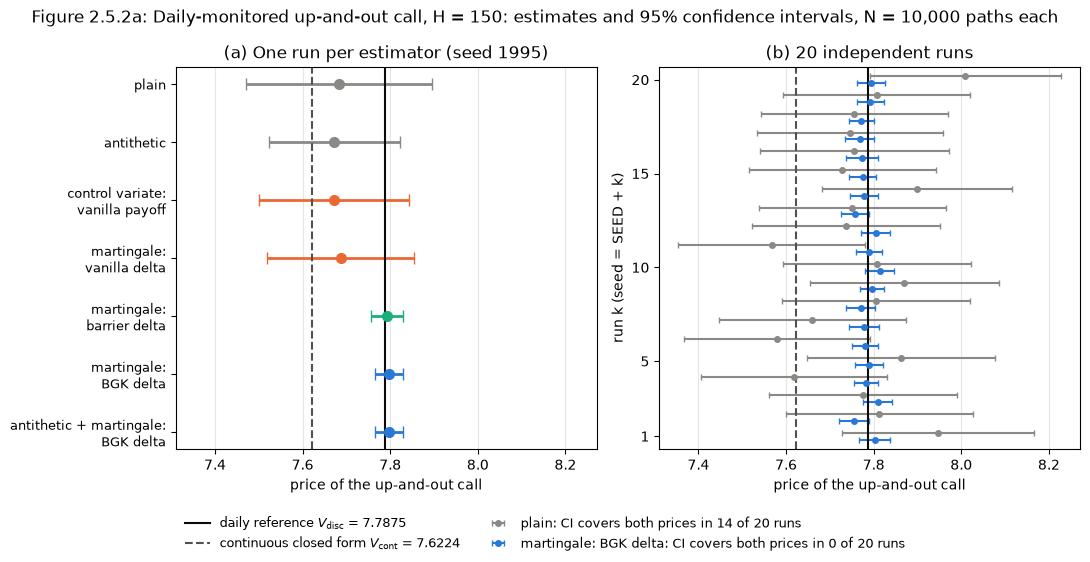

In [65]:
# Figure 2.5.2a: estimates and 95% CIs against the two benchmarks
mvr_colour = {'plain': '#8a8986', 'antithetic': '#8a8986', 'control variate: vanilla payoff': '#eb6834',
              'martingale: vanilla delta': '#eb6834', 'martingale: barrier delta': '#1baf7a',
              'martingale: BGK delta': '#2a78d6', 'antithetic + martingale: BGK delta': '#2a78d6'}
mvr_fig, (mvr_ax_a, mvr_ax_b) = plt.subplots(1, 2, figsize=(11, 5.6), sharex=True)

# (a) one run: every estimator of Table 2.5.2d, from top to bottom
mvr_row_positions = np.arange(len(bar_table))[::-1]
for mvr_position, mvr_name in zip(mvr_row_positions, bar_table.index):
    mvr_ax_a.errorbar(bar_table.loc[mvr_name, 'price'], mvr_position, xerr=1.96 * bar_table.loc[mvr_name, 'SE'],
                      fmt='o', ms=7, capsize=4, lw=2, color=mvr_colour[mvr_name])
mvr_ax_a.set_yticks(mvr_row_positions)
mvr_ax_a.set_yticklabels([mvr_name.replace(': ', ':\n') for mvr_name in bar_table.index], fontsize=9)
mvr_ax_a.set_title(f'(a) One run per estimator (seed {SEED})')

# (b) twenty independent runs: plain against the BGK-delta martingale control, offset vertically
for mvr_name, mvr_offset in (('plain', 0.18), ('martingale: BGK delta', -0.18)):
    mvr_runs = mvr_reps[mvr_reps['estimator'] == mvr_name]
    mvr_covers_both = int(mvr_rep_counts.loc[mvr_name, 'covers both'])
    mvr_ax_b.errorbar(mvr_runs['price'], np.arange(1, 21) + mvr_offset, xerr=1.96 * mvr_runs['SE'], fmt='o', ms=4,
                      capsize=2, lw=1.5, color=mvr_colour[mvr_name],
                      label=f'{mvr_name}: CI covers both prices in {mvr_covers_both} of 20 runs')
mvr_ax_b.set_ylabel('run k (seed = SEED + k)')
mvr_ax_b.set_yticks([1, 5, 10, 15, 20])
mvr_ax_b.set_ylim(0.3, 20.7)
mvr_ax_b.set_title('(b) 20 independent runs')

for mvr_axis in (mvr_ax_a, mvr_ax_b):                                # the two benchmarks on both panels
    mvr_axis.axvline(bar_V_disc, color='#0b0b0b', lw=1.5)
    mvr_axis.axvline(bar_V_cont, color='#52514e', lw=1.5, ls='--')
    mvr_axis.set_xlabel('price of the up-and-out call')
    mvr_axis.grid(axis='x', color='#e6e5e1', lw=0.8)
mvr_ax_b.plot([], [], color='#0b0b0b', lw=1.5, label=rf'daily reference $V_{{\mathrm{{disc}}}}$ = {bar_V_disc:.4f}')
mvr_ax_b.plot([], [], color='#52514e', lw=1.5, ls='--',
              label=rf'continuous closed form $V_{{\mathrm{{cont}}}}$ = {bar_V_cont:.4f}')
mvr_handles, mvr_labels = mvr_ax_b.get_legend_handles_labels()
mvr_fig.legend(mvr_handles, mvr_labels, loc='lower center', ncol=2, fontsize=9, frameon=False)
mvr_fig.suptitle(f'Figure 2.5.2a: Daily-monitored up-and-out call, H = {bar_H:.0f}: estimates and 95% confidence '
                 f'intervals, N = {mvr_N:,} paths each')
mvr_fig.tight_layout(rect=(0, 0.09, 1, 1))
plt.show()


In [66]:
# VRF of each martingale control against the barrier level, on the same 10,000 paths (data for Figure 2.5.2b)
bar_scan_rows = []
for bar_H_scan in (115.0, 120.0, 130.0, 140.0, 150.0, 170.0, 200.0, 250.0):
    bar_payoff_scan = bar_uoc_payoff(mvr_paths, K, bar_H_scan, T, r)
    bar_H_scan_bgk = bar_H_scan * np.exp(bar_beta * sigma * np.sqrt(bar_dt))
    bar_scan_hedges = {
        'vanilla delta': mvr_hedges['vanilla delta'],
        'barrier delta': lambda S, tau: bar_uoc_delta(S, K, bar_H_scan, tau, r, sigma),
        'BGK delta':     lambda S, tau: bar_uoc_delta(S, K, bar_H_scan_bgk, tau, r, sigma),
    }
    bar_scan_row = {'H': bar_H_scan,
                    'knocked out': 1 - np.all(mvr_paths[:, 1:] < bar_H_scan, axis=1).mean(),
                    'plain price': bar_payoff_scan.mean()}
    bar_se_plain_scan = mvr_estimate(bar_payoff_scan)['SE']
    for mvr_name, mvr_hedge in bar_scan_hedges.items():
        bar_hedge_pnl_scan = mvr_martingale_control(mvr_paths, T, r, mvr_hedge, bar_H_scan)
        bar_se_controlled_scan = mvr_estimate(bar_payoff_scan, bar_hedge_pnl_scan)['SE']
        bar_scan_row[f'VRF, {mvr_name}'] = (bar_se_plain_scan / bar_se_controlled_scan)**2
    bar_scan_rows.append(bar_scan_row)

bar_scan = pd.DataFrame(bar_scan_rows).set_index('H')


Up-and-out delta, 1 year to expiry: negative above S = 116.3, lowest value -0.44
Up-and-out delta, 1 week to expiry: negative above S = 141.3, lowest value -8.26


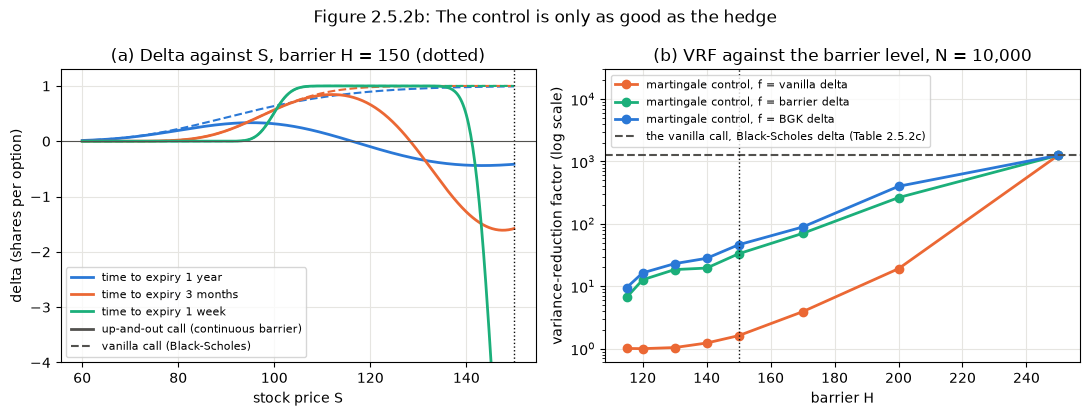

In [67]:
# Figure 2.5.2b: (a) the hedge ratios against S; (b) VRF against the barrier level
mvr_fig, (mvr_ax_a, mvr_ax_b) = plt.subplots(1, 2, figsize=(11, 4.2))
bar_S_plot = np.linspace(60, 149.9, 400)
for bar_tau, bar_tau_name, mvr_line_colour in ((1.0, '1 year', '#2a78d6'), (0.25, '3 months', '#eb6834'),
                                               (5 / 252, '1 week', '#1baf7a')):
    bar_delta_barrier = bar_uoc_delta(bar_S_plot, K, bar_H, bar_tau, r, sigma)
    bar_delta_vanilla = bs_greeks(bar_S_plot, K, bar_tau, r, sigma, 'call')['delta']
    mvr_ax_a.plot(bar_S_plot, bar_delta_barrier, color=mvr_line_colour, lw=2, label=f'time to expiry {bar_tau_name}')
    mvr_ax_a.plot(bar_S_plot, bar_delta_vanilla, color=mvr_line_colour, lw=1.5, ls='--')
    if bar_tau_name != '3 months':                                   # two facts quoted in the reading below
        print(f"Up-and-out delta, {bar_tau_name} to expiry: negative above "
              f"S = {bar_S_plot[bar_delta_barrier < 0].min():.1f}, lowest value {bar_delta_barrier.min():.2f}")
mvr_ax_a.plot([], [], color='#52514e', lw=2, label='up-and-out call (continuous barrier)')
mvr_ax_a.plot([], [], color='#52514e', lw=1.5, ls='--', label='vanilla call (Black-Scholes)')
mvr_ax_a.axvline(bar_H, color='#0b0b0b', lw=1, ls=':')
mvr_ax_a.axhline(0, color='#52514e', lw=0.8)
mvr_ax_a.set_ylim(-4, 1.3)
mvr_ax_a.set_xlabel('stock price S')
mvr_ax_a.set_ylabel('delta (shares per option)')
mvr_ax_a.set_title(f'(a) Delta against S, barrier H = {bar_H:.0f} (dotted)')
mvr_ax_a.legend(loc='lower left', fontsize=8)

for mvr_name, mvr_line_colour in (('vanilla delta', '#eb6834'), ('barrier delta', '#1baf7a'), ('BGK delta', '#2a78d6')):
    mvr_ax_b.plot(bar_scan.index, bar_scan[f'VRF, {mvr_name}'], 'o-', color=mvr_line_colour, lw=2, ms=6,
                  label=f'martingale control, f = {mvr_name}')
mvr_ax_b.axhline(mvr_call.loc['martingale control, alpha*', 'VRF'], color='#52514e', lw=1.5, ls='--',
                 label="the vanilla call, Black-Scholes delta (Table 2.5.2c)")
mvr_ax_b.axvline(bar_H, color='#0b0b0b', lw=1, ls=':')
mvr_ax_b.set_yscale('log')
mvr_ax_b.set_ylim(0.6, 3e4)                                          # head room for the legend
mvr_ax_b.set_xlabel('barrier H')
mvr_ax_b.set_ylabel('variance-reduction factor (log scale)')
mvr_ax_b.set_title(f'(b) VRF against the barrier level, N = {mvr_N:,}')
mvr_ax_b.legend(loc='upper left', fontsize=8)
for mvr_axis in (mvr_ax_a, mvr_ax_b):
    mvr_axis.grid(color='#e6e5e1', lw=0.8)
mvr_fig.suptitle('Figure 2.5.2b: The control is only as good as the hedge')
mvr_fig.tight_layout()
plt.show()


**The cost of the hedge.** The barrier delta is expensive. It needs nine evaluations of the normal distribution
function $N(\cdot)$ on every path at every date, against two for the vanilla delta and none for plain sampling. A
cheaper route is to rebalance less often. Table 2.5.2e rebalances every 1, 2, 5, 10 or 21 trading days and holds the
position in between. $Y$ is still a martingale, because each holding is set using only what is known at its
rebalancing date.

For the vanilla call we can predict the result. Over a rebalancing interval $h$, the hedge leaves the gamma term of
Itô's lemma uncovered (§1.2), about $\tfrac12\Gamma S^2\sigma^2(\phi^2-1)\,h$. Its variance is of order $h^2$,
and there are $T/h$ intervals, so the variance of the hedging error is proportional to $h$. The VRF should therefore be
proportional to the number of rebalancing dates.


In [68]:
# Table 2.5.2e: rebalance the hedge every few days; the control stays a martingale and costs less to compute
mvr_se_plain_call = mvr_estimate(mvr_payoff_call)['SE']
bar_se_plain = mvr_estimate(bar_payoff)['SE']
mvr_rebal_rows = []
for mvr_every in (1, 2, 5, 10, 21):                                  # trading days between rebalancing dates
    mvr_hedge_dates = len(range(0, bar_n_dates, mvr_every))          # rebalancing at steps 0, k, 2k, ...
    mvr_hedge_pnl_every = mvr_martingale_control(mvr_paths, T, r, mvr_hedges['vanilla delta'],
                                                 hedge_every=mvr_every)
    mvr_vrf_call = (mvr_se_plain_call / mvr_estimate(mvr_payoff_call, mvr_hedge_pnl_every)['SE'])**2
    mvr_t0 = time.perf_counter()
    bar_hedge_pnl_every = mvr_martingale_control(mvr_paths, T, r, mvr_hedges['BGK delta'], bar_H,
                                                 hedge_every=mvr_every)
    mvr_t_every = mvr_t_paths + time.perf_counter() - mvr_t0
    bar_vrf_every = (bar_se_plain / mvr_estimate(bar_payoff, bar_hedge_pnl_every)['SE'])**2
    mvr_rebal_rows.append({'days between rebalancing': mvr_every,
                           'hedge dates': mvr_hedge_dates,
                           "vanilla call: VRF": mvr_vrf_call,
                           "vanilla call: VRF per hedge date": mvr_vrf_call / mvr_hedge_dates,
                           'barrier, BGK delta: VRF': bar_vrf_every,
                           'barrier: efficiency': bar_vrf_every * mvr_t_paths / mvr_t_every})

mvr_rebal = pd.DataFrame(mvr_rebal_rows).set_index('days between rebalancing')
print(f"Table 2.5.2e: rebalancing the hedge less often, N = {mvr_N:,} "
      f"(efficiency = VRF x t_plain / t; run times are machine-dependent)\n")
print(mvr_rebal.to_string(formatters={"vanilla call: VRF": '{:.1f}'.format,
                                      "vanilla call: VRF per hedge date": '{:.2f}'.format,
                                      'barrier, BGK delta: VRF': '{:.1f}'.format,
                                      'barrier: efficiency': '{:.1f}'.format}))


Table 2.5.2e: rebalancing the hedge less often, N = 10,000 (efficiency = VRF x t_plain / t; run times are machine-dependent)

                          hedge dates vanilla call: VRF vanilla call: VRF per hedge date barrier, BGK delta: VRF barrier: efficiency
days between rebalancing                                                                                                            
1                                 252            1264.4                             5.02                    46.3                 2.1
2                                 126             637.1                             5.06                    31.3                 3.0
5                                  51             274.8                             5.39                    16.9                 3.4
10                                 26             139.4                             5.36                    10.2                 3.2
21                                 12              67.0                     

**Path accuracy.** Table 2.5.2f prices the barrier and the vanilla call with the three schemes of §1.8, on the same
50,000 sets of 252 draws (the first 10,000 are those used above). It also counts the paths whose knock-out status
differs from the exact path.


In [69]:
# Table 2.5.2f: Euler-Maruyama, Milstein and exact daily paths on the same draws
mvr_Z_schemes = np.random.default_rng(SEED).standard_normal((50_000, bar_n_dates))
bar_scheme_results = {}
for mvr_scheme, mvr_scheme_function in SCHEMES.items():
    mvr_paths_scheme = mvr_scheme_function(S0, r, sigma, T, mvr_Z_schemes)
    bar_scheme_results[mvr_scheme] = {
        'S_T': mvr_paths_scheme[:, -1].copy(),                       # a copy, so the paths can be freed
        'alive': np.all(mvr_paths_scheme[:, 1:] < bar_H, axis=1),
        'barrier': bar_uoc_payoff(mvr_paths_scheme, K, bar_H, T, r),
        'vanilla': np.exp(-r * T) * payoff(mvr_paths_scheme[:, -1], K, 'call')}
    del mvr_paths_scheme                                             # free 100 MB before the next scheme
del mvr_Z_schemes

bar_exact_result = bar_scheme_results['exact']
bar_scheme_rows = []
for mvr_scheme in ('euler', 'milstein', 'exact'):
    bar_result = bar_scheme_results[mvr_scheme]
    bar_difference_barrier = bar_result['barrier'] - bar_exact_result['barrier']   # paired, path by path
    bar_difference_vanilla = bar_result['vanilla'] - bar_exact_result['vanilla']
    bar_scheme_rows.append({
        'scheme': mvr_scheme,
        'mean |S_T - exact S_T|': np.mean(np.abs(bar_result['S_T'] - bar_exact_result['S_T'])),
        'knock-outs flipped': int(np.sum(bar_result['alive'] != bar_exact_result['alive'])),
        'barrier price': bar_result['barrier'].mean(),
        'barrier: minus exact': bar_difference_barrier.mean(),
        'barrier: SE of difference': bar_difference_barrier.std(ddof=1) / np.sqrt(bar_difference_barrier.size),
        'vanilla price': bar_result['vanilla'].mean(),
        'vanilla: minus exact': bar_difference_vanilla.mean(),
        'vanilla: SE of difference': bar_difference_vanilla.std(ddof=1) / np.sqrt(bar_difference_vanilla.size)})

bar_schemes = pd.DataFrame(bar_scheme_rows).set_index('scheme')
print("Table 2.5.2f: the three schemes on the same 50,000 x 252 draws (paired differences against the exact paths)\n")
print(bar_schemes.to_string(float_format=lambda value: f'{value:.5f}'))


Table 2.5.2f: the three schemes on the same 50,000 x 252 draws (paired differences against the exact paths)

          mean |S_T - exact S_T|  knock-outs flipped  barrier price  barrier: minus exact  barrier: SE of difference  vanilla price  vanilla: minus exact  vanilla: SE of difference
scheme                                                                                                                                                                              
euler                    0.14896                  39        7.72445               0.00397                    0.00505       10.30269               0.00013                    0.00068
milstein                 0.00349                   0        7.71928              -0.00120                    0.00001       10.30079              -0.00177                    0.00001
exact                    0.00000                   0        7.72048               0.00000                    0.00000       10.30257               0.00000              

**Reading the results.** The daily benchmark is 7.7875, compared with 7.6224 for continuous
monitoring. Their difference is small enough for the plain Monte Carlo interval to contain both at
$N=10{,}000$. The BGK-delta control reduces variance by a factor of 46.3 and resolves the two prices
(Table 2.5.2d, Figure 2.5.2a). The repeated runs show that this improvement is not confined to the first seed.
Figure 2.5.2b connects it to the hedge: the barrier's exposure near knockout differs substantially from the
vanilla call's exposure.

The gain comes with computational cost. In the reported timings, daily barrier-delta evaluation gives no
clear advantage over antithetic sampling at equal runtime. Weekly rebalancing retains a variance-reduction
factor of 16.9 while reducing hedge evaluations (Table 2.5.2e). This is why both precision per path and
efficiency per unit time are reported.

Finally, Euler changes the knockout status of 39 of the 50,000 shared paths relative to exact simulation;
Milstein changes none (Table 2.5.2f). The discontinuous payoff makes path accuracy relevant, although one
sample cannot establish that a scheme will always make the same knockout decisions as the exact paths.
